### Import the required libraries


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error, r2_score

#### Read the dataset

In [3]:
df = pd.read_excel('dataset/kerala_land_price_dataset.xlsx', sheet_name='Land_Data')

In [4]:
df.head()

,Year,District,Place,Land_Type,Road_Access,Distance_Town_km,Distance_Highway_m,Area_Cent,Land_Price_Per_Cent_INR,Source,Data_Status
0,2010,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,500,1,350000,NaN,Actual price required
1,2011,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.5,530,1,457000,NaN,Actual price required
2,2012,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,2.0,532,1,525000,NaN,Actual price required
3,2013,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,534,1,600000,NaN,Actual price required
4,2014,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,536,1,776000,NaN,Actual price required


##### Clean the text columns

In [6]:
df['Place'] = df['Place'].str.strip()
df['Land_Type'] = df['Land_Type'].str.strip()
df['Land_Type'] = df['Land_Type'].str.replace('Forntage', 'Frontage')

##### Check the unique values

In [7]:
df['Place'].unique()

array(['Kazhakkoottam', 'Akkulam', 'Vizhinjam', 'Pattom', 'Karyavattom',
       'Kavadior', 'East Fort'], dtype=object)

In [8]:
df['Land_Type'].unique()

array(['NH 66 Bypass Frontage', 'NH HIGHWAY Frontage',
       'Prime / Main Road / Commercial'], dtype=object)

#### Remove unnecessary columns


In [9]:
df = df.drop(columns=['District', 'Road_Access', 'Area_Cent', 'Source', 'Data_Status'])

### Rename the price column

In [10]:
df = df.rename(columns={'Land_Price_Per_Cent_INR': 'Price'})

In [11]:
df.head()

,Year,Place,Land_Type,Distance_Town_km,Distance_Highway_m,Price
0,2010,Kazhakkoottam,NH 66 Bypass Frontage,1.0,500,350000
1,2011,Kazhakkoottam,NH 66 Bypass Frontage,1.5,530,457000
2,2012,Kazhakkoottam,NH 66 Bypass Frontage,2.0,532,525000
3,2013,Kazhakkoottam,NH 66 Bypass Frontage,1.0,534,600000
4,2014,Kazhakkoottam,NH 66 Bypass Frontage,1.0,536,776000


#### Sort the data
Sorting by place and year keeps each place's yearly records in the correct order.

In [12]:
df = df.sort_values(['Place', 'Year'])
df = df.reset_index(drop=True)

In [13]:
df[['Place', 'Year', 'Price']].head(10)

,Place,Year,Price
0,Akkulam,2010,350000
1,Akkulam,2011,420000
2,Akkulam,2012,550000
3,Akkulam,2013,600000
4,Akkulam,2014,750000
5,Akkulam,2015,900000
6,Akkulam,2016,1000000
7,Akkulam,2017,1300000
8,Akkulam,2018,1500000
9,Akkulam,2019,1800000


#### Feature engineering
We create three useful columns:
- `t`: number of years after 2010.
- `log_price`: natural logarithm of price.
- `YoY_%`: percentage change from the previous year's price for the same place.

In [14]:
df['t'] = df['Year'] - 2010
df['log_price'] = np.log(df['Price'])
df['YoY_%'] = df.groupby('Place')['Price'].pct_change() * 100

In [15]:
df[['Place', 'Year', 'Price', 't', 'log_price', 'YoY_%']].head(10)

,Place,Year,Price,t,log_price,YoY_%
0,Akkulam,2010,350000,0,12.765688,NaN
1,Akkulam,2011,420000,1,12.948010,20.000000
2,Akkulam,2012,550000,2,13.217674,30.952381
3,Akkulam,2013,600000,3,13.304685,9.090909
4,Akkulam,2014,750000,4,13.527828,25.000000
5,Akkulam,2015,900000,5,13.710150,20.000000
6,Akkulam,2016,1000000,6,13.815511,11.111111
7,Akkulam,2017,1300000,7,14.077875,30.000000
8,Akkulam,2018,1500000,8,14.220976,15.384615
9,Akkulam,2019,1800000,9,14.403297,20.000000


#### Check possible outliers using IQR


In [16]:
q1 = df['YoY_%'].quantile(0.25)
q3 = df['YoY_%'].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print('Lower limit:', lower)
print('Upper limit:', upper)

Lower limit: -9.166666666666682
Upper limit: 37.5


In [17]:
outliers = df[(df['YoY_%'] < lower) | (df['YoY_%'] > upper)]
outliers[['Place', 'Year', 'Price', 'YoY_%']]

,Place,Year,Price,YoY_%
18,East Fort,2011,1400000,40.000000
37,Karyavattom,2013,600000,50.000000
38,Karyavattom,2014,900000,50.000000
39,Karyavattom,2015,1500000,66.666667
53,Kavadior,2012,600000,50.000000


## 12. Save the cleaned dataset
The EDA notebook will use this processed CSV file. Make sure the `dataset` folder exists.

In [19]:
df.to_csv('dataset/land_price_processed.csv', index=False)


In [20]:
df.shape

(119, 9)

#### Prepare yearly price data for modelling

`pivot()` changes the table so that:
- each row represents a year,
- each column represents a place,
- each value represents the price.

In [21]:
pivot = df.pivot(index='Year', columns='Place', values='Price')
pivot.head()

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
Year,,,,,,,
2010,350000,1000000,250000,350000,350000,1200000,400000
2011,420000,1400000,300000,400000,457000,1300000,500000
2012,550000,1800000,400000,600000,525000,1455000,600000
2013,600000,2000000,600000,800000,600000,1800000,700000
2014,750000,2500000,900000,1000000,776000,1978000,800000


#### Calculate historical CAGR
CAGR means Compound Annual Growth Rate. It gives the average yearly growth rate between the first and last year.

In [22]:
first_price = pivot.iloc[0]
last_price = pivot.iloc[-1]
number_of_years = pivot.index[-1] - pivot.index[0]

cagr = ((last_price / first_price) ** (1 / number_of_years) - 1) * 100
cagr

Place
Akkulam          16.261865
East Fort        18.441992
Karyavattom      20.590855
Kavadior         17.306352
Kazhakkoottam    14.370976
Pattom            9.329358
Vizhinjam        13.180374
dtype: float64

#### Split the data by year
We use 2010–2022 for training and 2023–2026 for testing. This is a time-based split.

In [23]:
train = pivot[pivot.index < 2023]
test = pivot[pivot.index >= 2023]

print('Training data:', train.shape)
print('Testing data:', test.shape)

Training data: (13, 7)
Testing data: (4, 7)


In [24]:
t_train = train.index.values - 2010
t_test = test.index.values - 2010

actual = test.values
places = pivot.columns

#### Naive model
This simple model predicts that each place's future price will stay equal to its last training-year price.

In [25]:
pred_naive = np.tile(train.values[-1], (len(test), 1))

#### Linear regression trend
`polyfit()` finds a straight-line trend for each place. We then use the equation to predict the test years.

In [26]:
coef_lin = np.polyfit(t_train, train.values, 1)
pred_lin = coef_lin[0] * t_test.reshape(-1, 1) + coef_lin[1]
pred_lin = np.maximum(pred_lin, 0)

#### Compound growth model
This model fits a straight line to log prices and converts the predictions back using `exp()`.

In [27]:
coef_comp = np.polyfit(t_train, np.log(train.values), 1)
pred_comp = np.exp(coef_comp[0] * t_test.reshape(-1, 1) + coef_comp[1])

#### Polynomial model
A degree-2 polynomial can represent a curved price trend.

In [28]:
coef_poly = np.polyfit(t_train, train.values, 2)
pred_poly = (coef_poly[0] * t_test.reshape(-1, 1) ** 2
             + coef_poly[1] * t_test.reshape(-1, 1)
             + coef_poly[2])
pred_poly = np.maximum(pred_poly, 0)

#### Prepare data for Random Forest and Gradient Boosting
`get_dummies()` converts the place names into numeric columns. We use the year and place to predict price.

In [29]:
X = pd.get_dummies(df[['Place', 'Year']], columns=['Place'])

X_train = X[df['Year'] < 2023]
X_test = X[df['Year'] >= 2023]

y_train = df.loc[df['Year'] < 2023, 'Price']
test_df = df[df['Year'] >= 2023].copy()

#### Random Forest model
Random Forest combines multiple decision trees to make a prediction.

In [30]:
rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)

rf_predictions = rf.predict(X_test)

#### Gradient Boosting model
Gradient Boosting builds trees step by step, with each new tree trying to improve the earlier predictions.

In [31]:
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

gb_predictions = gb.predict(X_test)

#### Arrange tree-model predictions by year and place
We convert the predictions into the same year-by-place format used by the other models.

In [32]:
test_pred = test_df[['Place', 'Year']].copy()
test_pred['rf'] = rf_predictions
test_pred['gb'] = gb_predictions

pred_rf = test_pred.pivot(index='Year', columns='Place', values='rf').values
pred_gb = test_pred.pivot(index='Year', columns='Place', values='gb').values

#### Evaluate the Naive model
MAE, RMSE, and MAPE measure prediction error. R² measures how well the predictions fit the actual values.

In [33]:
m_naive = pd.DataFrame({
    'MAE': mean_absolute_error(actual, pred_naive, multioutput='raw_values'),
    'RMSE': np.sqrt(mean_squared_error(actual, pred_naive, multioutput='raw_values')),
    'MAPE_%': mean_absolute_percentage_error(actual, pred_naive, multioutput='raw_values') * 100,
    'R2': r2_score(actual, pred_naive, multioutput='raw_values')
}, index=places)

m_naive

,MAE,RMSE,MAPE_%,R2
Place,,,,
Akkulam,936250.0,1.035739e+06,26.717916,-4.467885
East Fort,3625000.0,4.069705e+06,27.083333,-3.840183
Karyavattom,1075000.0,1.177922e+06,23.053032,-4.983827
Kavadior,800000.0,9.300538e+05,19.831731,-2.844444
Kazhakkoottam,586500.0,7.233941e+05,23.005827,-1.918294
Pattom,767500.0,9.272136e+05,16.777696,-2.176299
Vizhinjam,500000.0,5.787918e+05,18.884994,-2.941176


#### Evaluate the Linear model

In [34]:
m_lin = pd.DataFrame({
    'MAE': mean_absolute_error(actual, pred_lin, multioutput='raw_values'),
    'RMSE': np.sqrt(mean_squared_error(actual, pred_lin, multioutput='raw_values')),
    'MAPE_%': mean_absolute_percentage_error(actual, pred_lin, multioutput='raw_values') * 100,
    'R2': r2_score(actual, pred_lin, multioutput='raw_values')
}, index=places)

m_lin

,MAE,RMSE,MAPE_%,R2
Place,,,,
Akkulam,4.594368e+05,5.141942e+05,13.048626,-0.347636
East Fort,2.806868e+06,3.021049e+06,21.353938,-1.667175
Karyavattom,2.252747e+05,2.296815e+05,5.082638,0.772491
Kavadior,2.217033e+05,2.930856e+05,5.347486,0.618226
Kazhakkoottam,3.840549e+05,4.908961e+05,14.913372,-0.343873
Pattom,6.010082e+05,6.865736e+05,13.360352,-0.741550
Vizhinjam,1.752747e+05,2.102307e+05,6.566991,0.480036


#### Evaluate the Compound Growth model

In [35]:
m_comp = pd.DataFrame({
    'MAE': mean_absolute_error(actual, pred_comp, multioutput='raw_values'),
    'RMSE': np.sqrt(mean_squared_error(actual, pred_comp, multioutput='raw_values')),
    'MAPE_%': mean_absolute_percentage_error(actual, pred_comp, multioutput='raw_values') * 100,
    'R2': r2_score(actual, pred_comp, multioutput='raw_values')
}, index=places)

m_comp

,MAE,RMSE,MAPE_%,R2
Place,,,,
Akkulam,1.150233e+06,1.224759e+06,33.507846,-6.645738
East Fort,3.256118e+06,3.517619e+06,24.909370,-2.616041
Karyavattom,5.344072e+06,5.749994e+06,116.184591,-141.587328
Kavadior,2.483936e+06,2.614370e+06,63.735476,-29.377475
Kazhakkoottam,2.745986e+05,2.990555e+05,12.640421,0.501250
Pattom,1.367686e+05,1.508546e+05,3.110424,0.915923
Vizhinjam,7.507445e+05,7.767701e+05,29.537104,-6.098492


#### Evaluate the Polynomial model

In [36]:
m_poly = pd.DataFrame({
    'MAE': mean_absolute_error(actual, pred_poly, multioutput='raw_values'),
    'RMSE': np.sqrt(mean_squared_error(actual, pred_poly, multioutput='raw_values')),
    'MAPE_%': mean_absolute_percentage_error(actual, pred_poly, multioutput='raw_values') * 100,
    'R2': r2_score(actual, pred_poly, multioutput='raw_values')
}, index=places)

m_poly

,MAE,RMSE,MAPE_%,R2
Place,,,,
Akkulam,165283.466533,174966.379699,5.204520,0.843963
East Fort,615259.740260,675726.570513,4.638616,0.866563
Karyavattom,321778.221778,343796.266063,6.984387,0.490260
Kavadior,121578.421578,179235.820682,3.020547,0.857220
Kazhakkoottam,175512.987013,290790.833161,6.277168,0.528436
Pattom,438824.675325,521375.553217,9.650152,-0.004299
Vizhinjam,62887.112887,84801.563655,2.612071,0.915396


#### Evaluate the Random Forest model

In [37]:
m_rf = pd.DataFrame({
    'MAE': mean_absolute_error(actual, pred_rf, multioutput='raw_values'),
    'RMSE': np.sqrt(mean_squared_error(actual, pred_rf, multioutput='raw_values')),
    'MAPE_%': mean_absolute_percentage_error(actual, pred_rf, multioutput='raw_values') * 100,
    'R2': r2_score(actual, pred_rf, multioutput='raw_values')
}, index=places)

m_rf

,MAE,RMSE,MAPE_%,R2
Place,,,,
Akkulam,8.093833e+05,9.226557e+05,22.844143,-3.339080
East Fort,4.198333e+06,4.587797e+06,31.728395,-5.150978
Karyavattom,1.163467e+06,1.259178e+06,25.055162,-5.837864
Kavadior,8.479000e+05,9.715629e+05,21.111751,-3.195264
Kazhakkoottam,5.342567e+05,6.817235e+05,20.680721,-1.591765
Pattom,9.839200e+05,1.112999e+06,21.923688,-3.576691
Vizhinjam,4.205667e+05,5.117385e+05,15.663377,-2.080898


#### Evaluate the Gradient Boosting model

In [38]:
m_gb = pd.DataFrame({
    'MAE': mean_absolute_error(actual, pred_gb, multioutput='raw_values'),
    'RMSE': np.sqrt(mean_squared_error(actual, pred_gb, multioutput='raw_values')),
    'MAPE_%': mean_absolute_percentage_error(actual, pred_gb, multioutput='raw_values') * 100,
    'R2': r2_score(actual, pred_gb, multioutput='raw_values')
}, index=places)

m_gb

,MAE,RMSE,MAPE_%,R2
Place,,,,
Akkulam,9.084299e+05,1.010662e+06,25.868452,-4.206309
East Fort,3.650794e+06,4.092698e+06,27.292314,-3.895028
Karyavattom,1.064493e+06,1.168341e+06,22.815252,-4.886884
Kavadior,8.469367e+05,9.707223e+05,21.086008,-3.188008
Kazhakkoottam,5.676520e+05,7.081988e+05,22.166992,-1.796981
Pattom,8.248870e+05,9.752473e+05,18.142232,-2.513916
Vizhinjam,4.788509e+05,5.606230e+05,18.027240,-2.697626


#### Compare all models
This table shows the evaluation scores for every model and every place.

In [39]:
comparison = pd.concat({
    'Naive': m_naive,
    'Linear': m_lin,
    'Compound growth': m_comp,
    'Polynomial': m_poly,
    'Random Forest': m_rf,
    'Gradient Boosting': m_gb
}, names=['Model', 'Place'])

comparison

MAE          RMSE      MAPE_%  \
Model             Place                                                   
Naive             Akkulam        9.362500e+05  1.035739e+06   26.717916   
                  East Fort      3.625000e+06  4.069705e+06   27.083333   
                  Karyavattom    1.075000e+06  1.177922e+06   23.053032   
                  Kavadior       8.000000e+05  9.300538e+05   19.831731   
                  Kazhakkoottam  5.865000e+05  7.233941e+05   23.005827   
                  Pattom         7.675000e+05  9.272136e+05   16.777696   
                  Vizhinjam      5.000000e+05  5.787918e+05   18.884994   
Linear            Akkulam        4.594368e+05  5.141942e+05   13.048626   
                  East Fort      2.806868e+06  3.021049e+06   21.353938   
                  Karyavattom    2.252747e+05  2.296815e+05    5.082638   
                  Kavadior       2.217033e+05  2.930856e+05    5.347486   
                  Kazhakkoottam  3.840549e+05  4.908961e+05   14.913372   
                  Pattom         6.010082e+05  6.865736e+05   13.360352   
                  Vizhinjam      1.752747e+05  2.102307e+05    6.566991   
Compound growth   Akkulam        1.150233e+06  1.224759e+06   33.507846   
                  East Fort      3.256118e+06  3.517619e+06   24.909370   
                  Karyavattom    5.344072e+06  5.749994e+06  116.184591   
                  Kavadior       2.483936e+06  2.614370e+06   63.735476   
                  Kazhakkoottam  2.745986e+05  2.990555e+05   12.640421   
                  Pattom         1.367686e+05  1.508546e+05    3.110424   
                  Vizhinjam      7.507445e+05  7.767701e+05   29.537104   
Polynomial        Akkulam        1.652835e+05  1.749664e+05    5.204520   
                  East Fort      6.152597e+05  6.757266e+05    4.638616   
                  Karyavattom    3.217782e+05  3.437963e+05    6.984387   
                  Kavadior       1.215784e+05  1.792358e+05    3.020547   
                  Kazhakkoottam  1.755130e+05  2.907908e+05    6.277168   
                  Pattom         4.388247e+05  5.213756e+05    9.650152   
                  Vizhinjam      6.288711e+04  8.480156e+04    2.612071   
Random Forest     Akkulam        8.093833e+05  9.226557e+05   22.844143   
                  East Fort      4.198333e+06  4.587797e+06   31.728395   
                  Karyavattom    1.163467e+06  1.259178e+06   25.055162   
                  Kavadior       8.479000e+05  9.715629e+05   21.111751   
                  Kazhakkoottam  5.342567e+05  6.817235e+05   20.680721   
                  Pattom         9.839200e+05  1.112999e+06   21.923688   
                  Vizhinjam      4.205667e+05  5.117385e+05   15.663377   
Gradient Boosting Akkulam        9.084299e+05  1.010662e+06   25.868452   
                  East Fort      3.650794e+06  4.092698e+06   27.292314   
                  Karyavattom    1.064493e+06  1.168341e+06   22.815252   
                  Kavadior       8.469367e+05  9.707223e+05   21.086008   
                  Kazhakkoottam  5.676520e+05  7.081988e+05   22.166992   
                  Pattom         8.248870e+05  9.752473e+05   18.142232   
                  Vizhinjam      4.788509e+05  5.606230e+05   18.027240   

                                         R2  
Model             Place                      
Naive             Akkulam         -4.467885  
                  East Fort       -3.840183  
                  Karyavattom     -4.983827  
                  Kavadior        -2.844444  
                  Kazhakkoottam   -1.918294  
                  Pattom          -2.176299  
                  Vizhinjam       -2.941176  
Linear            Akkulam         -0.347636  
                  East Fort       -1.667175  
                  Karyavattom      0.772491  
                  Kavadior         0.618226  
                  Kazhakkoottam   -0.343873  
                  Pattom          -0.741550  
                  Vizhinjam        0.480036  
Compo

#### Find the average model scores
Lower MAE, RMSE, and MAPE usually mean smaller prediction errors.

In [40]:
summary = comparison.groupby('Model').mean().sort_values('RMSE')
summary

,MAE,RMSE,MAPE_%,R2
Model,,,,
Polynomial,2.715892e+05,3.243847e+05,5.483923,0.642506
Linear,6.962316e+05,7.779587e+05,11.381915,-0.175640
Naive,1.184321e+06,1.348974e+06,22.193504,-3.310301
Gradient Boosting,1.191721e+06,1.355213e+06,22.199784,-3.312107
Random Forest,1.279690e+06,1.435379e+06,22.715320,-3.538934
Compound growth,1.913781e+06,2.047632e+06,40.517890,-26.415414


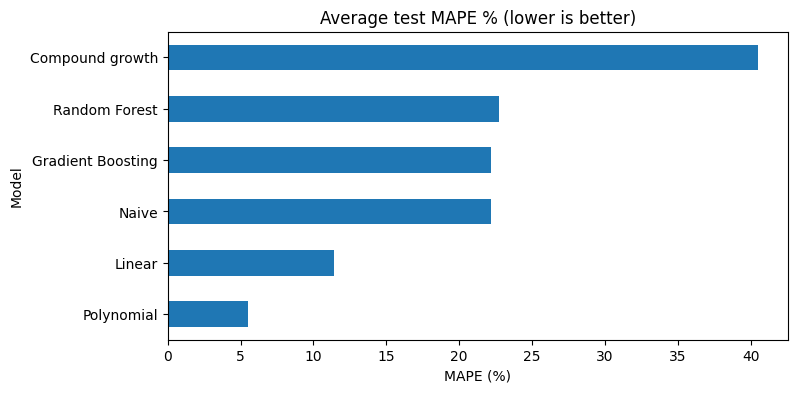

In [41]:
summary['MAPE_%'].sort_values().plot(kind='barh', figsize=(8, 4),
                                     title='Average test MAPE % (lower is better)')
plt.xlabel('MAPE (%)')
plt.show()

#### Select the best trend model for each place
For the long-term forecast, we compare Linear, Compound Growth, and Polynomial models using their test RMSE.

In [42]:
rmse_table = comparison['RMSE'].unstack(level=0)

trend_rmse = rmse_table[['Linear', 'Compound growth', 'Polynomial']]
best_model = trend_rmse.idxmin(axis=1)
best_rmse = trend_rmse.min(axis=1)

best_model_table = pd.DataFrame({
    'Best model': best_model,
    'RMSE': best_rmse
})

best_model_table

,Best model,RMSE
Place,,
Akkulam,Polynomial,174966.379699
East Fort,Polynomial,675726.570513
Karyavattom,Linear,229681.502436
Kavadior,Polynomial,179235.820682
Kazhakkoottam,Polynomial,290790.833161
Pattom,Compound growth,150854.604101
Vizhinjam,Polynomial,84801.563655


#### Fit the trend models using all available years
After comparing the models, we fit the three trend models again using the complete historical dataset.

In [43]:
t_all = pivot.index.values - 2010

final_lin = np.polyfit(t_all, pivot.values, 1)
final_comp = np.polyfit(t_all, np.log(pivot.values), 1)
final_poly = np.polyfit(t_all, pivot.values, 2)

#### View the model equations
These tables show the coefficients learned for each place.

In [44]:
eq_lin = pd.DataFrame(final_lin.T, index=places,
                      columns=['Slope', 'Intercept'])
eq_lin

,Slope,Intercept
Place,,
Akkulam,222977.941176,-41764.705882
East Fort,849264.705882,-594117.647059
Karyavattom,310539.215686,-63725.490196
Kavadior,251715.686275,95098.039216
Kazhakkoottam,140568.627451,163333.333333
Pattom,213963.235294,977235.294118
Vizhinjam,151225.490196,260784.313725


In [45]:
eq_poly = pd.DataFrame(final_poly.T, index=places,
                       columns=['t_squared', 't', 'constant'])
eq_poly

,t_squared,t,constant
Place,,,
Akkulam,9020.252838,78653.895769,3.190454e+05
East Fort,46375.128999,107262.641899,1.260888e+06
Karyavattom,1535.087719,285977.812178,-2.321981e+03
Kavadior,4192.466460,184636.222910,2.627967e+05
Kazhakkoottam,6961.816305,29179.566563,4.418060e+05
Pattom,9191.305470,66902.347781,1.344888e+06
Vizhinjam,3341.073271,97768.317853,3.944272e+05


In [46]:
eq_comp = pd.DataFrame({
    'Start price': np.exp(final_comp[1]),
    'Yearly growth %': (np.exp(final_comp[0]) - 1) * 100
}, index=places)

eq_comp

,Start price,Yearly growth %
Place,,
Akkulam,4.031980e+05,16.389738
East Fort,1.269204e+06,17.676247
Karyavattom,3.907077e+05,20.355000
Kavadior,4.901360e+05,16.432594
Kazhakkoottam,4.199832e+05,12.711470
Pattom,1.282220e+06,8.593851
Vizhinjam,4.913985e+05,12.501326


#### Forecast prices from 2027 to 2040
We use the final model coefficients to calculate future prices.

In [47]:
future_years = np.arange(2027, 2041)
t_future = future_years - 2010

In [48]:
fc_lin = final_lin[0] * t_future.reshape(-1, 1) + final_lin[1]
fc_lin = np.maximum(fc_lin, 0)

fc_comp = np.exp(final_comp[0] * t_future.reshape(-1, 1) + final_comp[1])

fc_poly = (final_poly[0] * t_future.reshape(-1, 1) ** 2
           + final_poly[1] * t_future.reshape(-1, 1)
           + final_poly[2])
fc_poly = np.maximum(fc_poly, 0)

#### Choose the best forecast for each place
We use the best trend model selected earlier for each place.

In [49]:
fc_best = np.where(best_model.values == 'Linear', fc_lin,
          np.where(best_model.values == 'Compound growth', fc_comp, fc_poly))

forecast = pd.DataFrame(fc_best, index=future_years, columns=places)
forecast

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
2027,4.263015e+06,1.648676e+07,5.215441e+06,4.613235e+06,2.949824e+06,5.207767e+06,3.022059e+06
2028,4.657377e+06,1.821716e+07,5.525980e+06,4.944608e+06,3.222667e+06,5.655315e+06,3.236765e+06
2029,5.069781e+06,2.004030e+07,5.836520e+06,5.284365e+06,3.509433e+06,6.141324e+06,3.458153e+06
2030,5.500224e+06,2.195619e+07,6.147059e+06,5.632508e+06,3.810124e+06,6.669100e+06,3.686223e+06
2031,5.948709e+06,2.396483e+07,6.457598e+06,5.989035e+06,4.124738e+06,7.242233e+06,3.920975e+06
2032,6.415233e+06,2.606623e+07,6.768137e+06,6.353947e+06,4.453276e+06,7.864619e+06,4.162410e+06
2033,6.899799e+06,2.826037e+07,7.078676e+06,6.727245e+06,4.795737e+06,8.540493e+06,4.410526e+06
2034,7.402405e+06,3.054727e+07,7.389216e+06,7.108927e+06,5.152122e+06,9.274450e+06,4.665325e+06
2035,7.923051e+06,3.292691e+07,7.699755e+06,7.498994e+06,5.522430e+06,1.007148e+07,4.926806e+06
2036,8.461738e+06,3.539930e+07,8.010294e+06,7.897446e+06,5.906663e+06,1.093701e+07,5.194969e+06


#### Calculate an uncertainty range
This gives a simple lower and upper range around the forecast using the selected model's test RMSE.

In [50]:
horizon = (future_years - 2026).reshape(-1, 1)
band = 1.96 * best_rmse.values * np.sqrt(horizon)

lower_df = pd.DataFrame(np.maximum(fc_best - band, 0),
                        index=future_years, columns=places)
upper_df = pd.DataFrame(fc_best + band,
                        index=future_years, columns=places)

In [51]:
lower_df.head()

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
2027,3.920081e+06,1.516234e+07,4.765265e+06,4.261933e+06,2.379873e+06,4.912092e+06,2.855848e+06
2028,4.172395e+06,1.634414e+07,4.889336e+06,4.447791e+06,2.416636e+06,5.237167e+06,3.001707e+06
2029,4.475801e+06,1.774633e+07,5.056792e+06,4.675892e+06,2.522251e+06,5.629200e+06,3.170267e+06
2030,4.814356e+06,1.930734e+07,5.246707e+06,4.929903e+06,2.670224e+06,6.077750e+06,3.353801e+06
2031,5.181885e+06,2.100333e+07,5.450974e+06,5.203499e+06,2.850291e+06,6.581083e+06,3.549316e+06


In [52]:
upper_df.head()

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
2027,4.605949e+06,1.781119e+07,5.665617e+06,4.964538e+06,3.519774e+06,5.503442e+06,3.188270e+06
2028,5.142360e+06,2.009018e+07,6.162625e+06,5.441424e+06,4.028698e+06,6.073462e+06,3.471823e+06
2029,5.663760e+06,2.233427e+07,6.616247e+06,5.892839e+06,4.496616e+06,6.653448e+06,3.746039e+06
2030,6.186093e+06,2.460504e+07,7.047410e+06,6.335112e+06,4.950024e+06,7.260450e+06,4.018645e+06
2031,6.715533e+06,2.692634e+07,7.464222e+06,6.774571e+06,5.399185e+06,7.903382e+06,4.292634e+06


#### Sanity check for 2040
We compare the 2040 forecast with the 2026 price and historical CAGR. This is a reasonableness check, not a guarantee of future prices.

In [53]:
check = pd.DataFrame({
    'Price_2026': pivot.loc[2026],
    'Forecast_2040': forecast.loc[2040],
    'Forecast_CAGR_%': ((forecast.loc[2040] / pivot.loc[2026]) ** (1 / 14) - 1) * 100,
    'Historical_CAGR_%': cagr
})

check

,Price_2026,Forecast_2040,Forecast_CAGR_%,Historical_CAGR_%
Place,,,,
Akkulam,3900000,1.079689e+07,7.544486,16.261865
East Fort,15000000,4.621638e+07,8.369602,18.441992
Karyavattom,5000000,9.252451e+06,4.494135,20.590855
Kavadior,4500000,9.575103e+06,5.541592,17.306352
Kazhakkoottam,3000000,7.582828e+06,6.847655,14.370976
Pattom,5000000,1.520966e+07,8.270635,9.329358
Vizhinjam,2900000,6.334443e+06,5.739307,13.180374


#### Plot historical prices and forecasts

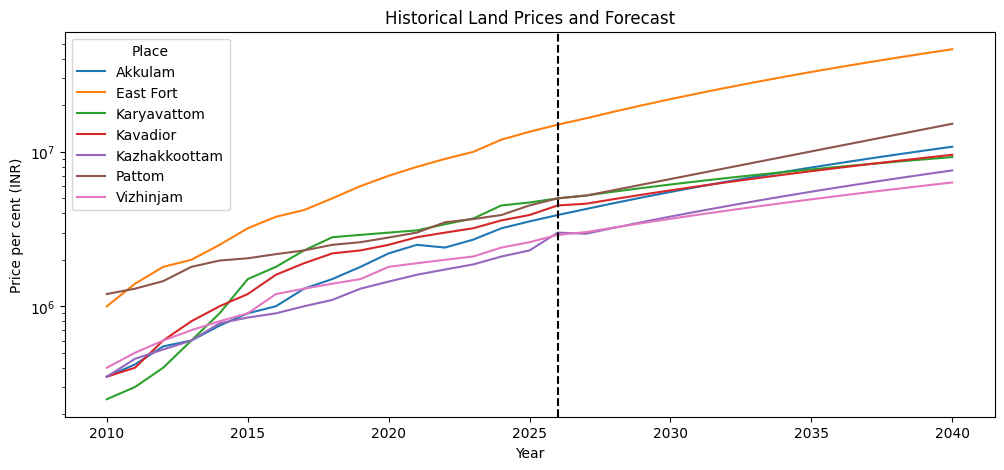

In [54]:
all_prices = pd.concat([pivot, forecast])

all_prices.plot(figsize=(12, 5), logy=True)
plt.axvline(2026, color='black', linestyle='--')
plt.title('Historical Land Prices and Forecast')
plt.xlabel('Year')
plt.ylabel('Price per cent (INR)')
plt.show()

#### Save the model files and results
These files can be loaded later by the Streamlit application or another Python program.

In [57]:
joblib.dump(final_lin, 'land_linear_coef.pkl')
joblib.dump(final_comp, 'land_compound_coef.pkl')
joblib.dump(final_poly, 'land_poly_coef.pkl')
joblib.dump(best_model, 'land_best_model.pkl')
joblib.dump(forecast, 'land_forecast.pkl')

forecast.to_csv('future_predictions.csv')
comparison.to_csv('model_comparison.csv')
summary.to_csv('model_summary.csv')



#### Example: predict the price for 2035
This cell loads the saved coefficients and calculates the 2035 price using the selected model for each place.

In [56]:
lin_c = joblib.load('land_linear_coef.pkl')
comp_c = joblib.load('land_compound_coef.pkl')
poly_c = joblib.load('land_poly_coef.pkl')
best = joblib.load('land_best_model.pkl')

t = 2035 - 2010

p_lin = lin_c[0] * t + lin_c[1]
p_comp = np.exp(comp_c[0] * t + comp_c[1])
p_poly = poly_c[0] * t**2 + poly_c[1] * t + poly_c[2]

p_2035 = np.where(best.values == 'Linear', p_lin,
         np.where(best.values == 'Compound growth', p_comp, p_poly))

pd.DataFrame({'Model': best, 'Price_2035': p_2035})

,Model,Price_2035
Place,,
Akkulam,Polynomial,7.923051e+06
East Fort,Polynomial,3.292691e+07
Karyavattom,Linear,7.699755e+06
Kavadior,Polynomial,7.498994e+06
Kazhakkoottam,Polynomial,5.522430e+06
Pattom,Compound growth,1.007148e+07
Vizhinjam,Polynomial,4.926806e+06
